#  Bike-Sharing Demand Analysis & Prediction
## Complete Data Science Mini Project — Google Colab

**Goal:** Analyze historical bike rentals, discover patterns, train regression models, and predict hourly demand.

**Dataset:** UCI Bike Sharing Dataset (`hour.csv`)  
**Target:** `cnt` — total bike rentals in an hour.

### Workflow
1. Problem definition
2. Dataset collection and understanding
3. Data quality inspection
4. Cleaning and preprocessing
5. Exploratory Data Analysis (EDA)
6. Feature preparation
7. Train/test split
8. Model training
9. Model evaluation
10. Findings and conclusion


## 1. Problem definition

Bike-sharing companies need to estimate how many bicycles customers may rent at different hours. Demand can vary with time, season, weather, and working-day patterns.

**Problem type:** Supervised Machine Learning — Regression, because the target is a numerical count.

**Objectives:** understand and clean the dataset, visualize demand patterns, train Linear Regression and Random Forest, compare MAE/RMSE/R², and interpret the results.

## 2. Import libraries

- Pandas and NumPy: data processing
- Matplotlib and Seaborn: visualization
- scikit-learn: preprocessing, model training, evaluation
- Requests and ZipFile: dataset download

In [17]:
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Collect the dataset

This downloads the official UCI Bike Sharing Dataset ZIP and reads the hourly file, `hour.csv`.


In [18]:
DATA_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    hourly_file = next(n for n in archive.namelist() if n.endswith("hour.csv"))
    with archive.open(hourly_file) as f:
        raw_df = pd.read_csv(f)

print("Dataset downloaded.")
print("Rows and columns:", raw_df.shape)
display(raw_df.head())

Dataset downloaded.
Rows and columns: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 4. Understand the data

Important variables:
- `dteday`: date
- `season`, `mnth`, `hr`, `weekday`: time variables
- `holiday`, `workingday`: calendar indicators
- `weathersit`: weather category
- `temp`, `atemp`, `hum`, `windspeed`: normalized weather measurements
- `casual`, `registered`: types of riders
- `cnt`: total rentals and the target variable

**Important:** `casual + registered = cnt`. Do not use `casual` or `registered` as model inputs, because that would leak the target answer into the model.

In [19]:
print("Shape:", raw_df.shape)
print("\nColumns:", raw_df.columns.tolist())
print("\nData types and non-null counts:")
raw_df.info()
print("\nMissing values:")
display(raw_df.isna().sum().to_frame("missing_values"))
print("\nDuplicate rows:", raw_df.duplicated().sum())
print("\nSummary statistics:")
display(raw_df.describe().T)

Shape: (17379, 17)

Columns: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14

,missing_values
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0



Duplicate rows: 0

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


## 5. Clean the data

We standardize column names, parse dates, remove duplicate rows, remove rows with a missing target, keep the target non-negative, and sort chronologically before splitting the data.

In [20]:
df = raw_df.copy()
df.columns = [str(c).strip().lower() for c in df.columns]
df["dteday"] = pd.to_datetime(df["dteday"], errors="coerce")

before = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = before - len(df)
before_target = len(df)
df = df.dropna(subset=["cnt"]).copy()
missing_target_removed = before_target - len(df)
df["cnt"] = df["cnt"].clip(lower=0)
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)

print("Original rows:", len(raw_df))
print("Duplicates removed:", duplicates_removed)
print("Rows removed for missing target:", missing_target_removed)
print("Rows after basic cleaning:", len(df))
display(df.isna().sum().to_frame("remaining_missing_values"))

Original rows: 17379
Duplicates removed: 0
Rows removed for missing target: 0
Rows after basic cleaning: 17379


,remaining_missing_values
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


## 6. Exploratory Data Analysis (EDA)\nEDA means exploring data with statistics and graphs before modeling.

### 6.1 Distribution of hourly rentals

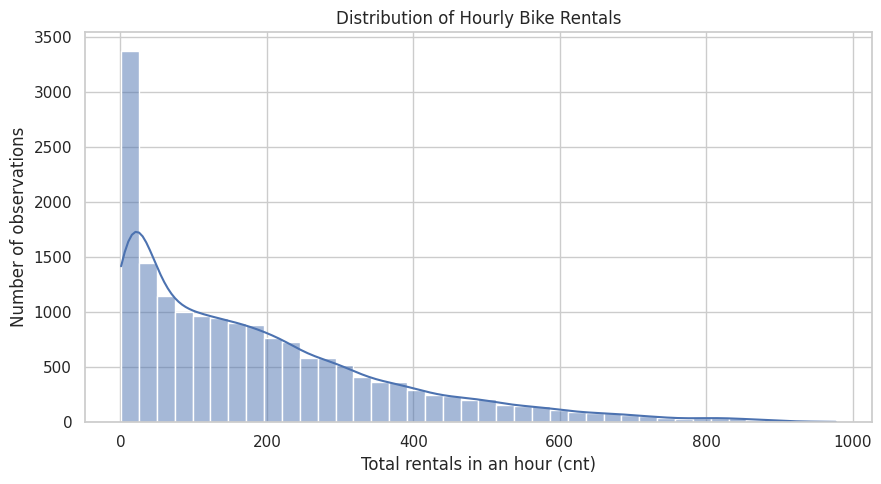

Mean: 189.46
Median: 142.0
Maximum: 977


In [21]:
plt.figure(figsize=(9,5))
sns.histplot(df["cnt"], bins=40, kde=True)
plt.title("Distribution of Hourly Bike Rentals")
plt.xlabel("Total rentals in an hour (cnt)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()
print("Mean:", round(df["cnt"].mean(), 2))
print("Median:", round(df["cnt"].median(), 2))
print("Maximum:", int(df["cnt"].max()))

### 6.2 Average demand by hour

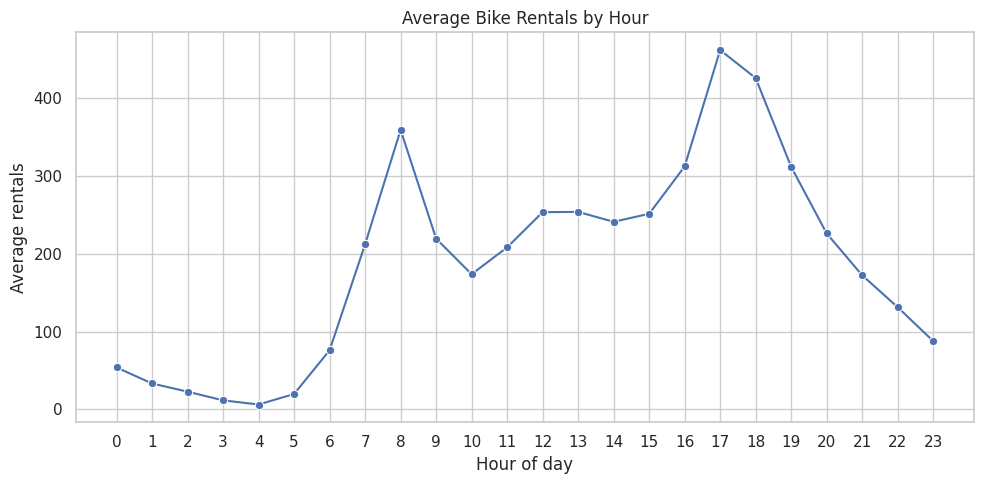

Highest average demand hour: 17:00


In [22]:
hourly = df.groupby("hr", as_index=False)["cnt"].mean()
plt.figure(figsize=(10,5))
sns.lineplot(data=hourly, x="hr", y="cnt", marker="o")
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals")
plt.xticks(range(24))
plt.tight_layout()
plt.show()
peak_hour = int(hourly.loc[hourly["cnt"].idxmax(), "hr"])
print("Highest average demand hour:", f"{peak_hour}:00")

### 6.3 Working days versus non-working days

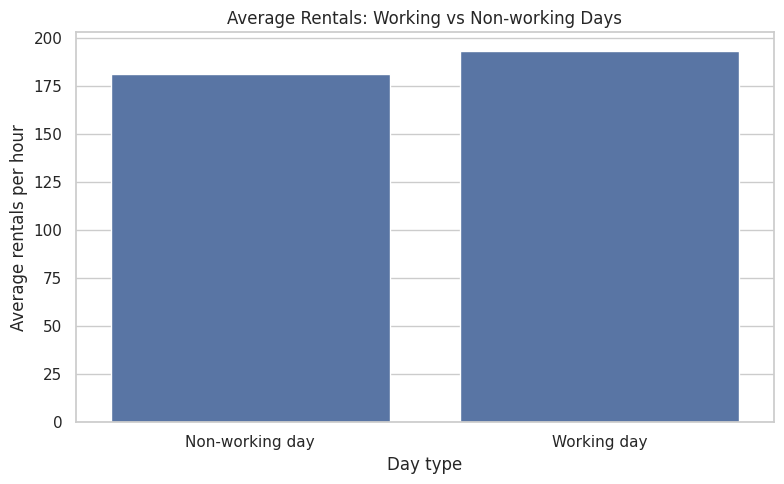

,count,mean,median,std
day_type,,,,
Non-working day,5514,181.41,119.0,172.85
Working day,11865,193.21,151.0,185.11


In [23]:
df["day_type"] = df["workingday"].map({0:"Non-working day", 1:"Working day"})
plt.figure(figsize=(8,5))
sns.barplot(data=df, x="day_type", y="cnt", estimator="mean", errorbar=None)
plt.title("Average Rentals: Working vs Non-working Days")
plt.xlabel("Day type")
plt.ylabel("Average rentals per hour")
plt.tight_layout()
plt.show()
display(df.groupby("day_type")["cnt"].agg(["count","mean","median","std"]).round(2))

### 6.4 Average demand by season

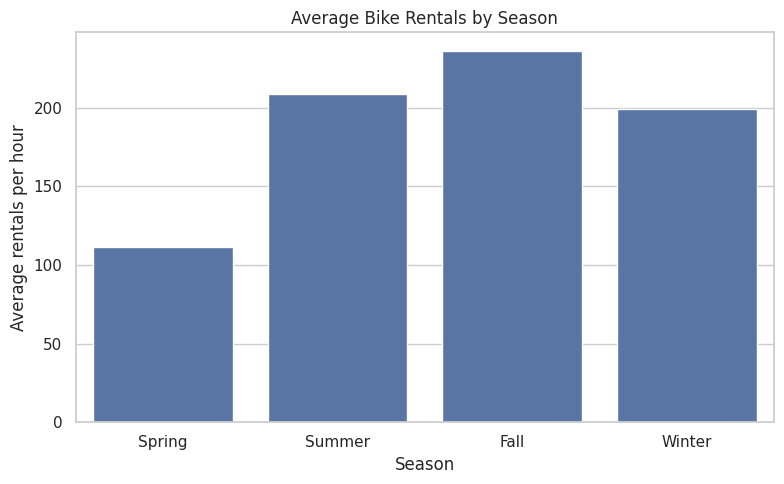

,season_name,cnt
0,Fall,236.02
2,Summer,208.34
3,Winter,198.87
1,Spring,111.11


In [24]:
season_labels = {1:"Spring", 2:"Summer", 3:"Fall", 4:"Winter"}
season_df = df.copy()
season_df["season_name"] = season_df["season"].map(season_labels)
season_summary = season_df.groupby("season_name", as_index=False)["cnt"].mean()
plt.figure(figsize=(8,5))
sns.barplot(data=season_summary, x="season_name", y="cnt",
            order=["Spring","Summer","Fall","Winter"], errorbar=None)
plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average rentals per hour")
plt.tight_layout()
plt.show()
display(season_summary.sort_values("cnt", ascending=False).round(2))

### 6.5 Weather and demand

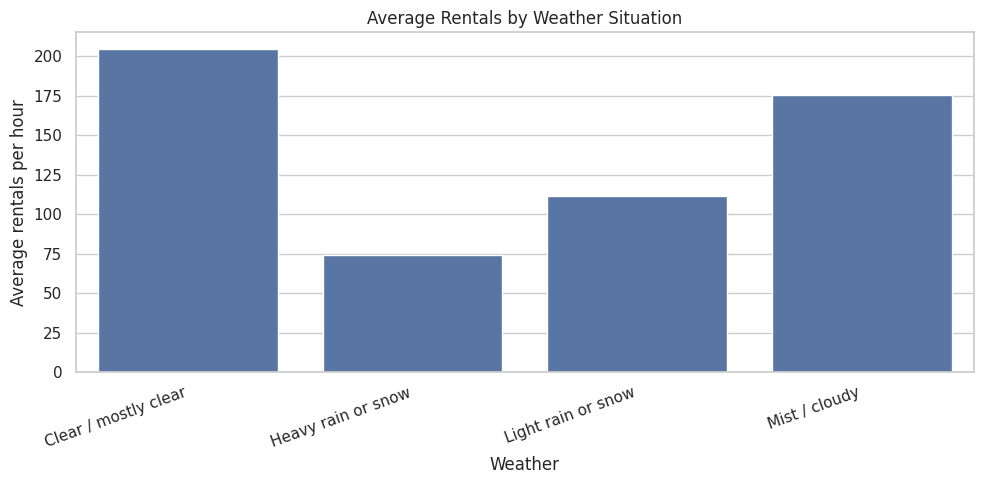

,weather_name,cnt
0,Clear / mostly clear,204.87
3,Mist / cloudy,175.17
2,Light rain or snow,111.58
1,Heavy rain or snow,74.33


In [25]:
weather_labels = {1:"Clear / mostly clear", 2:"Mist / cloudy",
                  3:"Light rain or snow", 4:"Heavy rain or snow"}
weather_df = df.copy()
weather_df["weather_name"] = weather_df["weathersit"].map(weather_labels)
weather_summary = weather_df.groupby("weather_name", as_index=False)["cnt"].mean()
plt.figure(figsize=(10,5))
sns.barplot(data=weather_summary, x="weather_name", y="cnt", errorbar=None)
plt.title("Average Rentals by Weather Situation")
plt.xlabel("Weather")
plt.ylabel("Average rentals per hour")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
display(weather_summary.sort_values("cnt", ascending=False).round(2))

### 6.6 Correlation heatmap

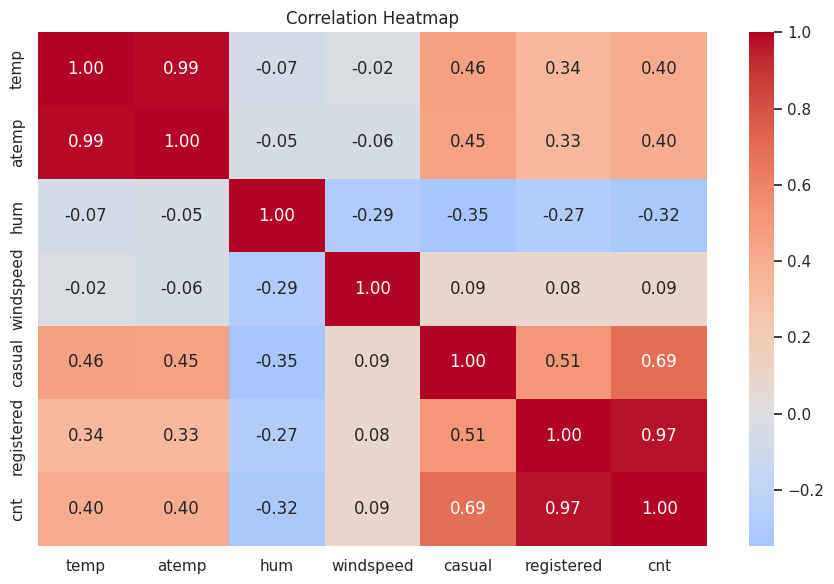

In [26]:
corr_cols = ["temp","atemp","hum","windspeed","casual","registered","cnt"]
plt.figure(figsize=(9,6))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 7. Feature selection and preprocessing

**Target (`y`):** `cnt`.

**Predictors (`X`):** season, year, month, hour, holiday, weekday, working-day status, weather category, temperature, feels-like temperature, humidity and wind speed.

**Excluded:** `casual` and `registered` because they add up to `cnt`; `instant` because it is an identifier; `dteday` is used for chronological sorting but not as a raw feature.

Categorical variables are one-hot encoded. Numeric values are imputed and scaled. The preprocessing pipeline is fitted on training data only.

In [27]:
categorical_features = ["season","yr","mnth","hr","holiday","weekday","workingday","weathersit"]
numeric_features = ["temp","atemp","hum","windspeed"]
features = categorical_features + numeric_features
target = "cnt"

X = df[features].copy()
y = df[target].astype(float).copy()

# Chronological holdout: first 80% train, last 20% test.
split = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Train period:", df["dteday"].iloc[0], "to", df["dteday"].iloc[split-1])
print("Test period:", df["dteday"].iloc[split], "to", df["dteday"].iloc[-1])
print("Feature columns:", features)

Training rows: 13903 | Test rows: 3476
Train period: 2011-01-01 00:00:00 to 2012-08-07 00:00:00
Test period: 2012-08-07 00:00:00 to 2012-12-31 00:00:00
Feature columns: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


## 8. Build preprocessing and train models

In [28]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

estimators = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=20, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    )
}
trained = {}
predictions = {}

for name, estimator in estimators.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    predictions[name] = np.maximum(0, pipe.predict(X_test))
    trained[name] = pipe
    print(name, "trained.")

Linear Regression trained.
Random Forest trained.


## 9. Evaluate the models

- **MAE:** average absolute prediction error in rentals; lower is better.
- **RMSE:** penalizes large errors more than MAE; lower is better.
- **R²:** compares performance with a mean-baseline predictor; higher is generally better and can be negative.

In [29]:
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })
results = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
display(results.round(3))

best_name = results.loc[0, "Model"]
best_model = trained[best_name]
best_pred = predictions[best_name]
print("Best model by lowest test RMSE:", best_name)

,Model,MAE,RMSE,R2
0,Random Forest,60.449,89.114,0.837
1,Linear Regression,98.691,133.819,0.632


Best model by lowest test RMSE: Random Forest


### 9.1 Compare model RMSE

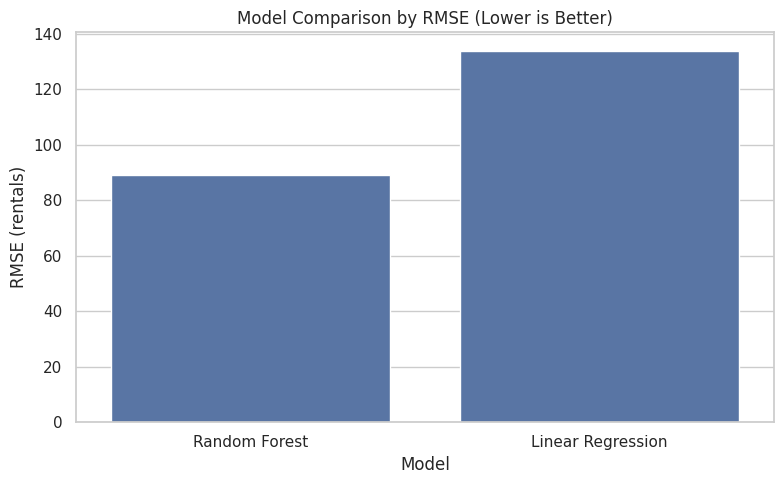

In [30]:
plt.figure(figsize=(8,5))
sns.barplot(data=results, x="Model", y="RMSE")
plt.title("Model Comparison by RMSE (Lower is Better)")
plt.ylabel("RMSE (rentals)")
plt.tight_layout()
plt.show()

### 9.2 Actual versus predicted

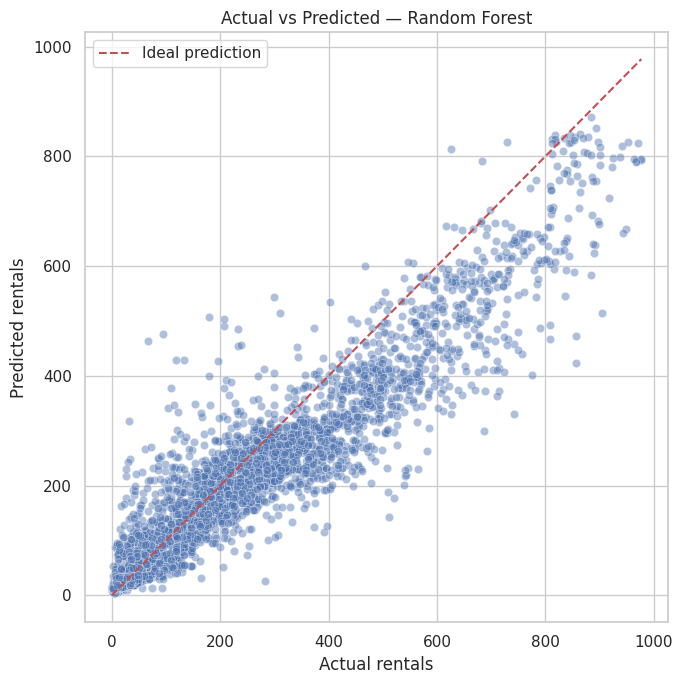

,Actual rentals,Predicted rentals
0,283.0,268.1
1,253.0,266.6
2,261.0,265.9
3,306.0,267.5
4,445.0,315.8
5,868.0,750.7
6,814.0,706.9
7,610.0,537.3
8,448.0,373.7
9,317.0,287.2


In [31]:
compare = pd.DataFrame({"Actual rentals": y_test.to_numpy(), "Predicted rentals": best_pred})
plt.figure(figsize=(7,7))
sns.scatterplot(data=compare, x="Actual rentals", y="Predicted rentals", alpha=.45)
upper = max(compare.max().max(), 1)
plt.plot([0, upper], [0, upper], "r--", label="Ideal prediction")
plt.title(f"Actual vs Predicted — {best_name}")
plt.legend()
plt.tight_layout()
plt.show()
display(compare.head(10).round(1))

## 10. Try one new prediction

The weather measurements below use the UCI dataset's normalized 0–1 scale, not degrees Celsius, percentage humidity, or km/h.

In [32]:
sample = pd.DataFrame([{
    "season": 2, "yr": 1, "mnth": 6, "hr": 8,
    "holiday": 0, "weekday": 2, "workingday": 1, "weathersit": 1,
    "temp": 0.55, "atemp": 0.53, "hum": 0.60, "windspeed": 0.20
}])[features]

estimate = max(0, float(best_model.predict(sample)[0]))
display(sample)
print(f"Estimated rentals in this hour: {estimate:.0f}")
print("This is a model estimate, not a guarantee.")

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,2,1,6,8,0,2,1,1,0.55,0.53,0.6,0.2


Estimated rentals in this hour: 670
This is a model estimate, not a guarantee.


## 11. Findings, conclusion and limitations

Fill this section with your actual outputs after running the notebook.

- Peak average demand hour: 17:00 (5:00 PM).
- Highest average-demand season: Fall, with approximately 236 rentals per hour.
- Working-day pattern: Working days have a higher average demand of 193.21 rentals per hour compared to 181.41 rentals per hour on non-working days.
- Weather pattern: Bike demand is highest during clear or mostly clear weather (204.87 rentals per hour) and lowest during heavy rain or snow (74.33 rentals per hour).
- Best model by test RMSE: Random Forest.
- Best model MAE / RMSE / R²: 60.449 / 89.114 / 0.837.

### Conclusion
This project followed a Data Science workflow to inspect, clean, visualize, and model hourly bike-sharing demand. EDA was used to explore patterns related to time and weather. Linear Regression and Random Forest were trained and evaluated on a held-out later portion of the dataset. The model with the lowest RMSE performed best on this particular split. The trained model can estimate hourly demand from selected conditions.

### Limitations
- This uses historical data, not live inventory or live weather.
- The weather variables are normalized.
- One chronological holdout is appropriate for a mini project but is not full time-series validation.
- Results depend on the dataset and model settings.

